# 04 - Análise dos Dados

Este notebook tem como objetivo analisar os indicadores financeiros da base de dados da CTI, investigando a evolução dos resultados ao longo dos 12 anos e as diferenças de desempenho entre os 1.200 cenários simulados.

A análise busca responder a perguntas de negócio relacionadas à receita, rentabilidade, geração de caixa e estrutura financeira, identificando padrões relevantes para a interpretação dos resultados.

Os resultados serão utilizados para fundamentar a construção do dashboard, orientar a escolha de visualizações e apoiar a elaboração de insights para a tomada de decisão.

Esta etapa utiliza os dados e indicadores preparados nos notebooks anteriores, evitando a repetição das etapas de exploração, tratamento e cálculo dos KPIs.

localizando planilha pivotada

In [28]:
from pathlib import Path

# Localiza a raiz do projeto
pasta_projeto = Path.cwd().parent

print("Pasta do projeto:", pasta_projeto)

# Procura a planilha dentro do projeto
arquivos = list(pasta_projeto.rglob("Analise_Financeira.xlsx"))

if arquivos:
    for arquivo in arquivos:
        print("Planilha encontrada:", arquivo)
else:
    print("Planilha não encontrada. Vamos conferir a estrutura das pastas.")

Pasta do projeto: c:\Users\rafae\OneDrive\Documentos\GitHub\Projeto1
Planilha encontrada: c:\Users\rafae\OneDrive\Documentos\GitHub\Projeto1\documentos\entrega 1\contabilidade e finanças\Analise_Financeira.xlsx


ler xlsx

In [29]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


abas da planilha

In [ ]:
import pandas as pd
from pathlib import Path

caminho_planilha = (
    pasta_projeto
    / "documentos"
    / "entrega 1"
    / "contabilidade e finanças"
    / "Analise_Financeira.xlsx"
)

# Lista as abas e suas dimensões
excel = pd.ExcelFile(caminho_planilha)

for aba in excel.sheet_names:
    df_aba = pd.read_excel(caminho_planilha, sheet_name=aba)

    print(f"\nAba: {aba}")
    print(f"Linhas: {df_aba.shape[0]} | Colunas: {df_aba.shape[1]}")
    print("Colunas:", list(df_aba.columns))


Aba: Dicionário de KPIs financeiros
Linhas: 19 | Colunas: 4
Colunas: ['Dicionário de KPIs financeiros', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']

Aba: Demonstrações contábeis
Linhas: 77 | Colunas: 13
Colunas: ['Demonstrações contábeis', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']

Aba: Indicadores - Índices
Linhas: 19 | Colunas: 13
Colunas: ['Indicadores / Índices financeiros', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']

Aba: Ranking
Linhas: 30 | Colunas: 14
Colunas: ['Ranking dos Cenários e Anos', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']

Aba: Análise Comparativa
Linhas: 17 | Colunas: 13
Co

In [ ]:
# Carrega a base de indicadores existente na planilha
df_indicadores = pd.read_excel(
    caminho_planilha,
    sheet_name="_Indicadores"
)

# Visualiza as primeiras linhas
display(df_indicadores.head())

# Confere tipos de dados e valores ausentes
df_indicadores.info()

# Confere os anos e a quantidade de cenários
print("\nAnos disponíveis:")
print(sorted(df_indicadores["Ano"].dropna().unique()))

print("\nQuantidade de cenários distintos:")
print(df_indicadores["Cenario"].nunique())

print("\nValores ausentes por coluna:")
display(df_indicadores.isnull().sum().to_frame("Valores ausentes"))

,Cenario,Ano,Margem EBITDA,Margem Líquida,LC,LS,LI,LG,PCT,CE,IPL,NOPAT,Capital Investido,ROIC,WACC,EVA,MVA Aproximado,EBITDA
0,Total Cen_00001,Ano 1,0.829973,0.390840,1.661277,1.661197,1.115028,0.282561,4.277473,0.125446,4.068824,2.812862e+06,6.737529e+06,0.417492,0.08,2.273859e+06,2.842324e+07,5.188381e+06
1,Total Cen_00001,Ano 2,0.825317,0.356584,1.154874,1.154811,0.753056,0.278254,6.085068,0.152663,5.391876,2.324825e+06,6.416736e+06,0.362306,0.08,1.811486e+06,2.264357e+07,4.630952e+06
2,Total Cen_00001,Ano 3,0.853486,0.371077,1.301103,1.301054,0.992276,0.376489,6.137439,0.189511,4.826759,2.428926e+06,5.785050e+06,0.419863,0.08,1.966122e+06,2.457653e+07,4.883290e+06
3,Total Cen_00001,Ano 4,0.865342,0.389656,3.324041,3.323867,2.243316,0.376906,4.982482,0.062000,4.104556,2.554873e+06,6.983079e+06,0.365866,0.08,1.996226e+06,2.495283e+07,5.148066e+06
4,Total Cen_00001,Ano 5,0.871756,0.422448,0.664478,0.664409,0.243336,0.250630,4.902671,0.143564,3.266220,2.818760e+06,9.176816e+06,0.307161,0.08,2.084614e+06,2.605768e+07,5.453240e+06


<class 'pandas.DataFrame'>
RangeIndex: 14400 entries, 0 to 14399
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Cenario            14400 non-null  str    
 1   Ano                14400 non-null  str    
 2   Margem EBITDA      14400 non-null  float64
 3   Margem Líquida     14400 non-null  float64
 4   LC                 14400 non-null  float64
 5   LS                 13200 non-null  float64
 6   LI                 14400 non-null  float64
 7   LG                 13200 non-null  float64
 8   PCT                13200 non-null  float64
 9   CE                 13200 non-null  float64
 10  IPL                13200 non-null  float64
 11  NOPAT              14400 non-null  float64
 12  Capital Investido  13200 non-null  float64
 13  ROIC               13200 non-null  float64
 14  WACC               14400 non-null  float64
 15  EVA                13200 non-null  float64
 16  MVA Aproximado     13200 non-null

,Valores ausentes
Cenario,0
Ano,0
Margem EBITDA,0
Margem Líquida,0
LC,0
LS,1200
LI,0
LG,1200
PCT,1200
CE,1200


In [ ]:
# Exibe apenas as primeiras linhas, sem o índice do DataFrame
display(df_indicadores.head(10).reset_index(drop=True))

# Confere os nomes reais das colunas
print("\nColunas:")
print(df_indicadores.columns.tolist())

# Confere os valores únicos de cenário e ano
print("\nExemplos de cenários:")
print(df_indicadores["Cenario"].unique()[:5])

print("\nAnos disponíveis:")
print(df_indicadores["Ano"].unique())

,Cenario,Ano,Margem EBITDA,Margem Líquida,LC,LS,LI,LG,PCT,CE,IPL,NOPAT,Capital Investido,ROIC,WACC,EVA,MVA Aproximado,EBITDA
0,Total Cen_00001,Ano 1,0.829973,0.390840,1.661277,1.661197,1.115028,0.282561,4.277473,0.125446,4.068824,2.812862e+06,6.737529e+06,0.417492,0.08,2.273859e+06,2.842324e+07,5.188381e+06
1,Total Cen_00001,Ano 2,0.825317,0.356584,1.154874,1.154811,0.753056,0.278254,6.085068,0.152663,5.391876,2.324825e+06,6.416736e+06,0.362306,0.08,1.811486e+06,2.264357e+07,4.630952e+06
2,Total Cen_00001,Ano 3,0.853486,0.371077,1.301103,1.301054,0.992276,0.376489,6.137439,0.189511,4.826759,2.428926e+06,5.785050e+06,0.419863,0.08,1.966122e+06,2.457653e+07,4.883290e+06
3,Total Cen_00001,Ano 4,0.865342,0.389656,3.324041,3.323867,2.243316,0.376906,4.982482,0.062000,4.104556,2.554873e+06,6.983079e+06,0.365866,0.08,1.996226e+06,2.495283e+07,5.148066e+06
4,Total Cen_00001,Ano 5,0.871756,0.422448,0.664478,0.664409,0.243336,0.250630,4.902671,0.143564,3.266220,2.818760e+06,9.176816e+06,0.307161,0.08,2.084614e+06,2.605768e+07,5.453240e+06
5,Total Cen_00001,Ano 6,0.878105,0.444770,0.395148,0.395105,0.133008,0.251326,4.793570,0.209836,2.577095,3.055476e+06,1.027130e+07,0.297477,0.08,2.233772e+06,2.792215e+07,5.834764e+06
6,Total Cen_00001,Ano 7,0.884270,0.447076,0.379970,0.379935,0.172747,0.288164,4.650721,0.247296,2.010339,3.224144e+06,1.113197e+07,0.289629,0.08,2.333587e+06,2.916983e+07,6.236914e+06
7,Total Cen_00001,Ano 8,0.888241,0.454888,0.764404,0.764366,0.588516,0.415432,4.142171,0.236112,1.465344,3.481231e+06,1.073254e+07,0.324362,0.08,2.622628e+06,3.278285e+07,6.693782e+06
8,Total Cen_00001,Ano 9,0.892089,0.466832,0.809218,0.809186,0.704683,0.458381,3.850995,0.266129,1.036045,3.731434e+06,1.079803e+07,0.345566,0.08,2.867592e+06,3.584490e+07,7.136917e+06
9,Total Cen_00001,Ano 10,0.897302,0.496918,0.646628,0.646606,0.610827,0.431964,3.651045,0.336053,0.620034,4.150515e+06,1.119421e+07,0.370773,0.08,3.254978e+06,4.068723e+07,7.653142e+06



Colunas:
['Cenario', 'Ano', 'Margem EBITDA', 'Margem Líquida', 'LC', 'LS', 'LI', 'LG', 'PCT', 'CE', 'IPL', 'NOPAT', 'Capital Investido', 'ROIC', 'WACC', 'EVA', 'MVA Aproximado', 'EBITDA']

Exemplos de cenários:
<StringArray>
['Total Cen_00001', 'Total Cen_00002', 'Total Cen_00003', 'Total Cen_00004',
 'Total Cen_00005']
Length: 5, dtype: str

Anos disponíveis:
<StringArray>
[ 'Ano 1',  'Ano 2',  'Ano 3',  'Ano 4',  'Ano 5',  'Ano 6',  'Ano 7',
  'Ano 8',  'Ano 9', 'Ano 10', 'Ano 11', 'Ano 12']
Length: 12, dtype: str


resumo anual dos indicadores - Essa célula calcula a média, a mediana e os percentis 10 e 90 de alguns indicadores para cada ano. Assim, conseguimos observar tanto o comportamento típico quanto a variação entre cenários.

In [ ]:
# Indicadores selecionados para a primeira análise
indicadores_selecionados = [
    "Margem EBITDA",
    "Margem Líquida",
    "EBITDA",
    "ROIC",
    "EVA"
]

# Resumo dos indicadores por ano, considerando todos os cenários
resumo_anual = (
    df_indicadores
    .groupby("Ano")[indicadores_selecionados]
    .agg(["mean", "median"])
)

# Organiza os anos na ordem correta
ordem_anos = sorted(
    df_indicadores["Ano"].unique(),
    key=lambda ano: int(ano.split()[1])
)

resumo_anual = resumo_anual.reindex(ordem_anos)

display(resumo_anual.round(4))

Margem EBITDA         Margem Líquida                EBITDA  \
                mean  median           mean  median          mean   
Ano                                                                 
Ano 1         0.8295  0.8295         0.3890  0.3913  5.152102e+06   
Ano 2         0.8260  0.8260         0.3520  0.3554  4.615494e+06   
Ano 3         0.8553  0.8556         0.3692  0.3720  4.896584e+06   
Ano 4         0.8678  0.8681         0.3865  0.3904  5.169079e+06   
Ano 5         0.8747  0.8751         0.4212  0.4240  5.472535e+06   
Ano 6         0.8811  0.8814         0.4454  0.4469  5.836869e+06   
Ano 7         0.8874  0.8877         0.4481  0.4494  6.221629e+06   
Ano 8         0.8915  0.8918         0.4554  0.4567  6.650721e+06   
Ano 9         0.8952  0.8955         0.4649  0.4674  7.061535e+06   
Ano 10        0.9003  0.9005         0.4931  0.4962  7.543996e+06   
Ano 11        0.9014  0.9016         0.5238  0.5268  8.007699e+06   
Ano 12        1.0456  1.0468         0.6313  0.6343  1.142586e+07   

                        ROIC                   EVA                
              median    mean  median          mean        median  
Ano                                                               
Ano 1   5.142975e+06  0.4103  0.4135  2.243242e+06  2.245657e+06  
Ano 2   4.613350e+06  0.3561  0.3612  1.791617e+06  1.802821e+06  
Ano 3   4.897521e+06  0.4154  0.4224  1.965402e+06  1.978748e+06  
Ano 4   5.173049e+06  0.3639  0.3685  2.002302e+06  2.014212e+06  
Ano 5   5.474861e+06  0.3093  0.3092  2.097257e+06  2.100693e+06  
Ano 6   5.834809e+06  0.2990  0.2981  2.237660e+06  2.239483e+06  
Ano 7   6.221455e+06  0.2901  0.2896  2.329408e+06  2.331956e+06  
Ano 8   6.649395e+06  0.3223  0.3230  2.599753e+06  2.607680e+06  
Ano 9   7.057399e+06  0.3405  0.3422  2.822415e+06  2.833715e+06  
Ano 10  7.535968e+06  0.3627  0.3642  3.181560e+06  3.191907e+06  
Ano 11  7.995440e+06  0.4037  0.4048  3.641320e+06  3.648166e+06  
Ano 12  1.140949e+07     NaN     NaN           NaN           NaN

gráfico de evolução dos indicadores

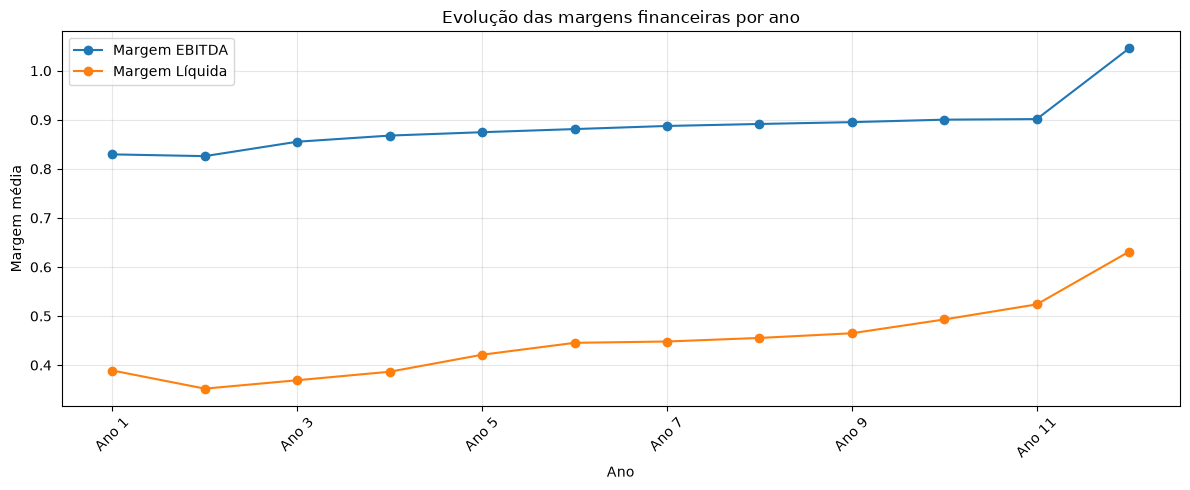

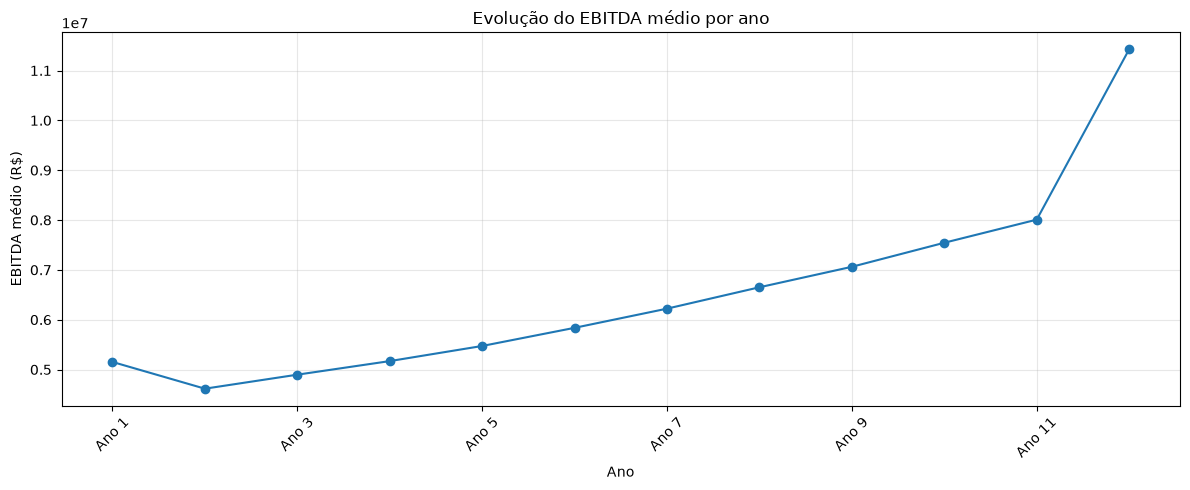

In [ ]:
import matplotlib.pyplot as plt

# Calcula a média dos indicadores por ano
evolucao = (
    df_indicadores
    .groupby("Ano")[
        ["Margem EBITDA", "Margem Líquida", "EBITDA"]
    ]
    .mean()
)

# Ordena os anos numericamente
evolucao = evolucao.reindex(
    sorted(evolucao.index, key=lambda ano: int(ano.split()[1]))
)

# Gráfico das margens
evolucao[["Margem EBITDA", "Margem Líquida"]].plot(
    marker="o",
    figsize=(12, 5)
)

plt.title("Evolução das margens financeiras por ano")
plt.xlabel("Ano")
plt.ylabel("Margem média")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfico do EBITDA médio
evolucao["EBITDA"].plot(
    marker="o",
    figsize=(12, 5)
)

plt.title("Evolução do EBITDA médio por ano")
plt.xlabel("Ano")
plt.ylabel("EBITDA médio (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Compara os dois últimos anos
comparacao_final = (
    df_indicadores[
        df_indicadores["Ano"].isin(["Ano 11", "Ano 12"])
    ]
    .groupby("Ano")[
        ["Margem EBITDA", "Margem Líquida", "EBITDA", "ROIC", "EVA"]
    ]
    .agg(["mean", "median", "count"])
)

display(comparacao_final.round(4))

Margem EBITDA               Margem Líquida                      EBITDA  \
                mean  median count           mean  median count          mean   
Ano                                                                             
Ano 11        0.9014  0.9016  1200         0.5238  0.5268  1200  8.007699e+06   
Ano 12        1.0456  1.0468  1200         0.6313  0.6343  1200  1.142586e+07   

                              ROIC                         EVA                \
              median count    mean  median count          mean        median   
Ano                                                                            
Ano 11  7.995440e+06  1200  0.4037  0.4048  1200  3.641320e+06  3.648166e+06   
Ano 12  1.140949e+07  1200     NaN     NaN     0           NaN           NaN   

              
       count  
Ano           
Ano 11  1200  
Ano 12     0

In [ ]:
# Verifica os valores disponíveis no Ano 12
colunas_verificacao = [
    "Capital Investido",
    "NOPAT",
    "ROIC",
    "WACC",
    "EVA",
    "MVA Aproximado"
]

ano_12 = df_indicadores[
    df_indicadores["Ano"] == "Ano 12"
]

print("Quantidade de registros no Ano 12:", len(ano_12))

display(
    ano_12[colunas_verificacao]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)
# No Ano 12, temos:
# - NOPAT: 1.200 valores disponíveis.
# - WACC: 1.200 valores disponíveis.
# - Capital Investido: nenhum valor disponível.
# - ROIC, EVA e MVA Aproximado: nenhum valor disponível.
 # Isso sugere que a ausência desses três indicadores está relacionada à falta de Capital Investido, mas ainda precisamos confirmar a fórmula e a origem dessa ausência. Não vamos preencher esses valores artificialmente.

Quantidade de registros no Ano 12: 1200


,Capital Investido,NOPAT,ROIC,WACC,EVA,MVA Aproximado
count,0.0,1200.00,0.0,1200.00,0.0,0.0
mean,NaN,5801419.38,NaN,0.08,NaN,NaN
min,NaN,4353924.92,NaN,0.08,NaN,NaN
max,NaN,7277129.18,NaN,0.08,NaN,NaN


capital investido na origem - mostra, para cada um dos 12 anos, quantos cenários têm Capital Investido preenchido e quantos estão sem valor.

In [ ]:
# Verifica os valores de Capital Investido por ano
verificacao_capital = (
    df_indicadores
    .groupby("Ano")["Capital Investido"]
    .agg(
        valores_disponiveis="count",
        valores_ausentes=lambda serie: serie.isna().sum()
    )
)

verificacao_capital = verificacao_capital.reindex(
    sorted(
        verificacao_capital.index,
        key=lambda ano: int(ano.split()[1])
    )
)

display(verificacao_capital)

,valores_disponiveis,valores_ausentes
Ano,,
Ano 1,1200,0
Ano 2,1200,0
Ano 3,1200,0
Ano 4,1200,0
Ano 5,1200,0
Ano 6,1200,0
Ano 7,1200,0
Ano 8,1200,0
Ano 9,1200,0


resultado análise exploratória:

In [ ]:
# Registro das descobertas da análise exploratória

observacoes_analise = [
    "A média da Margem EBITDA, da Margem Líquida e do EBITDA "
    "apresentou evolução crescente ao longo dos anos analisados.",

    "No Ano 12, o Capital Investido está ausente nos 1.200 cenários.",

    "ROIC, EVA e MVA Aproximado também não apresentam valores "
    "disponíveis no Ano 12.",

    "A ausência desses indicadores deve ser investigada na origem "
    "dos dados e nas regras de cálculo antes de qualquer tratamento.",

    "Os indicadores ausentes não devem ser preenchidos artificialmente."
]

for i, observacao in enumerate(observacoes_analise, start=1):
    print(f"{i}. {observacao}")

1. A média da Margem EBITDA, da Margem Líquida e do EBITDA apresentou evolução crescente ao longo dos anos analisados.
2. No Ano 12, o Capital Investido está ausente nos 1.200 cenários.
3. ROIC, EVA e MVA Aproximado também não apresentam valores disponíveis no Ano 12.
4. A ausência desses indicadores deve ser investigada na origem dos dados e nas regras de cálculo antes de qualquer tratamento.
5. Os indicadores ausentes não devem ser preenchidos artificialmente.


a partir daqui, começamos a etapa de distribuição dos resultados entre os 1.200 cenários.

análise de distribuição do EBITDA

In [ ]:
# Estatísticas do EBITDA por ano, considerando os 1.200 cenários
distribuicao_ebitda = (
    df_indicadores
    .groupby("Ano")["EBITDA"]
    .agg(
        quantidade="count",
        media="mean",
        mediana="median",
        desvio_padrao="std",
        minimo="min",
        maximo="max"
    )
)

# Ordena os anos numericamente
distribuicao_ebitda = distribuicao_ebitda.reindex(
    sorted(
        distribuicao_ebitda.index,
        key=lambda ano: int(ano.split()[1])
    )
)

display(distribuicao_ebitda.round(2))

,quantidade,media,mediana,desvio_padrao,minimo,maximo
Ano,,,,,,
Ano 1,1200,5152102.09,5142974.87,30472.64,4946467.41,5323231.23
Ano 2,1200,4615494.38,4613350.24,35644.60,4320029.15,4910685.92
Ano 3,1200,4896584.09,4897521.11,48946.14,4501312.69,5331443.76
Ano 4,1200,5169078.82,5173048.57,64508.99,4653106.23,5744370.04
Ano 5,1200,5472534.55,5474860.76,81071.79,4821219.98,6201411.34
Ano 6,1200,5836868.80,5834809.36,99197.75,5030614.05,6731229.75
Ano 7,1200,6221628.54,6221454.97,120836.25,5241241.48,7300969.98
Ano 8,1200,6650720.92,6649395.48,145640.35,5482134.36,7931389.82
Ano 9,1200,7061535.49,7057399.36,173689.14,5691537.95,8561544.74


grafico da distirbuição do EBITDA

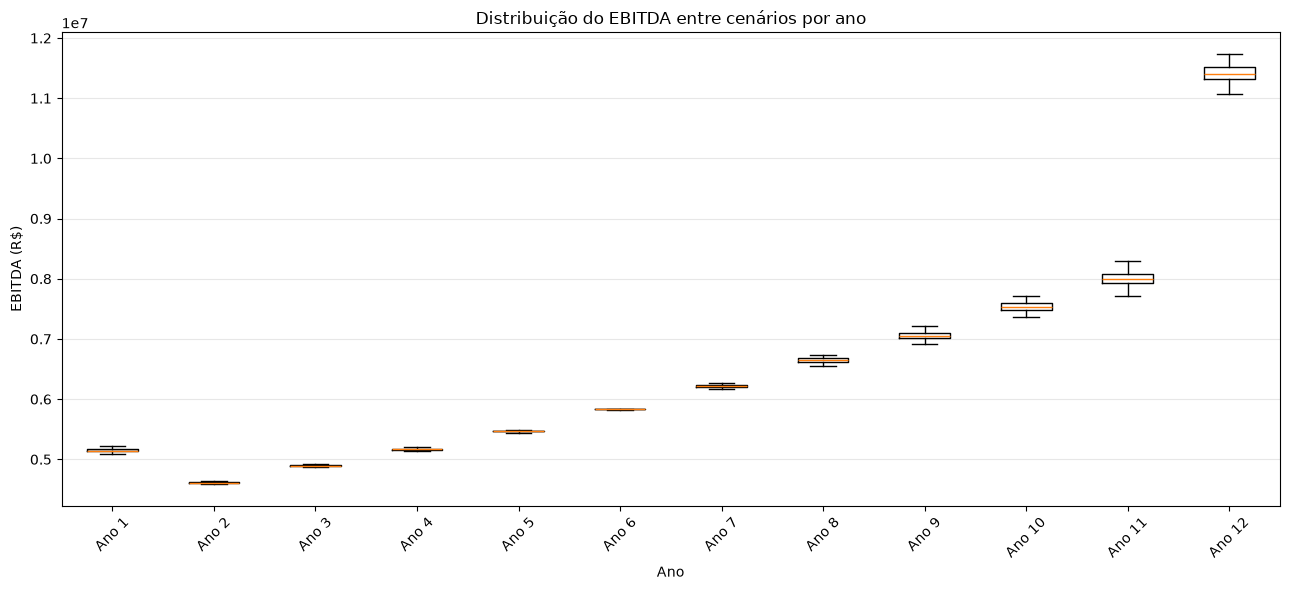

In [ ]:
import matplotlib.pyplot as plt

# Separa o EBITDA por ano
anos = sorted(
    df_indicadores["Ano"].unique(),
    key=lambda ano: int(ano.split()[1])
)

dados_ebitda = [
    df_indicadores.loc[
        df_indicadores["Ano"] == ano, "EBITDA"
    ].dropna()
    for ano in anos
]

# Cria o boxplot
plt.figure(figsize=(13, 6))
plt.boxplot(dados_ebitda, tick_labels=anos, showfliers=False)

plt.title("Distribuição do EBITDA entre cenários por ano")
plt.xlabel("Ano")
plt.ylabel("EBITDA (R$)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
distribuicao_ebitda["coeficiente_variacao_%"] = (
    distribuicao_ebitda["desvio_padrao"]
    / distribuicao_ebitda["media"]
) * 100

display(
    distribuicao_ebitda[
        ["media", "desvio_padrao", "coeficiente_variacao_%"]
    ].round(2)
)

,media,desvio_padrao,coeficiente_variacao_%
Ano,,,
Ano 1,5152102.09,30472.64,0.59
Ano 2,4615494.38,35644.60,0.77
Ano 3,4896584.09,48946.14,1.00
Ano 4,5169078.82,64508.99,1.25
Ano 5,5472534.55,81071.79,1.48
Ano 6,5836868.80,99197.75,1.70
Ano 7,6221628.54,120836.25,1.94
Ano 8,6650720.92,145640.35,2.19
Ano 9,7061535.49,173689.14,2.46


O coeficiente de variação aumenta de 0,59% no Ano 1 para 3,03% no Ano 11, indicando que a dispersão do EBITDA entre os cenários cresce também proporcionalmente à média. No Ano 12, ele cai para 2,46%, mesmo com o aumento expressivo do EBITDA médio.
Isso significa que, no Ano 12, os valores de EBITDA estão mais dispersos em termos absolutos, mas a dispersão é menor em relação à média do que no Ano 11.

conclusão em codigo

In [ ]:
print("CONCLUSÃO — DISTRIBUIÇÃO DO EBITDA")
print("-" * 45)
print(
    "O coeficiente de variação aumenta do Ano 1 ao Ano 11, "
    "indicando crescimento da dispersão relativa do EBITDA entre os cenários."
)
print(
    "No Ano 12, o coeficiente cai para 2,46%, apesar do aumento "
    "do EBITDA médio. Esse comportamento merece investigação."
)
print(
    "Os resultados descrevem os dados disponíveis e não comprovam, "
    "por si só, as causas das variações observadas."
)

CONCLUSÃO — DISTRIBUIÇÃO DO EBITDA
---------------------------------------------
O coeficiente de variação aumenta do Ano 1 ao Ano 11, indicando crescimento da dispersão relativa do EBITDA entre os cenários.
No Ano 12, o coeficiente cai para 2,46%, apesar do aumento do EBITDA médio. Esse comportamento merece investigação.
Os resultados descrevem os dados disponíveis e não comprovam, por si só, as causas das variações observadas.


a partir daqui iremos fazer a analise de comparação e ranking dos cenários

estrutura das abas na planilha

In [ ]:
ranking = pd.read_excel(
    caminho_planilha,
    sheet_name="Ranking"
)

analise_comparativa = pd.read_excel(
    caminho_planilha,
    sheet_name="Análise Comparativa"
)

print("TOP 10 — MELHORES COMBINAÇÕES")
display(ranking.iloc[5:16, :9])

print("ÚLTIMAS POSIÇÕES DISPONÍVEIS NA ABA")
display(ranking.tail(10).iloc[:, :9])

print("ANÁLISE COMPARATIVA — TODOS OS ANOS")
display(analise_comparativa.iloc[4:, :13])

TOP 10 — MELHORES COMBINAÇÕES


,Ranking dos Cenários e Anos,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
5,Posição,Cenário,Ano,Rentabilidade,Liquidez,Estrutura de Capital,Geração de Valor,Pontuação Final,NaN
6,1,Total Cen_01128,Ano 11,91.559028,90.257734,67.659091,100,86.102388,NaN
7,2,Total Cen_01127,Ano 11,91.159722,90.239741,67.65404,99.992424,86.020489,NaN
8,3,Total Cen_01126,Ano 11,90.5,90.174558,67.64899,99.984848,85.874082,NaN
9,4,Total Cen_01128,Ano 9,83.756944,90.230271,70.665404,98.681818,85.254075,NaN
10,5,Total Cen_01127,Ano 9,83.6875,90.183081,70.622475,96.795455,84.869605,NaN
11,6,Total Cen_01128,Ano 10,87.565972,86.483112,69.607323,99.931818,84.522727,NaN
12,7,Total Cen_01125,Ano 11,89.722222,86.481218,67.643939,99.977273,84.38688,NaN
13,8,Total Cen_01127,Ano 10,87.552083,86.376263,68.993687,99.909091,84.30986,NaN
14,9,Total Cen_01124,Ano 11,88.75,86.35827,67.636364,99.969697,84.161961,NaN


ÚLTIMAS POSIÇÕES DISPONÍVEIS NA ABA


,Ranking dos Cenários e Anos,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
20,1,Total Cen_01128,Ano 11,0.914008,0.530541,1.865615,1.865596,1.87213,0.903501
21,2,Total Cen_01127,Ano 11,0.913483,0.52937,1.781133,1.781114,1.787648,0.87211
22,3,Total Cen_01126,Ano 11,0.912952,0.528184,1.697311,1.697292,1.703826,0.840965
23,4,Total Cen_01128,Ano 9,0.907076,0.480585,1.827726,1.827695,1.72563,0.733307
24,5,Total Cen_01127,Ano 9,0.906578,0.479142,1.746243,1.746212,1.644148,0.711007
25,6,Total Cen_01128,Ano 10,0.912129,0.504078,1.627058,1.627036,1.590875,0.764697
26,7,Total Cen_01125,Ano 11,0.912414,0.526984,1.614145,1.614126,1.62066,0.810063
27,8,Total Cen_01127,Ano 10,0.911631,0.502733,1.551463,1.551441,1.51528,0.738737
28,9,Total Cen_01124,Ano 11,0.911869,0.52577,1.531629,1.53161,1.538144,0.779404
29,10,Total Cen_01126,Ano 10,0.911127,0.501373,1.476406,1.476384,1.440223,0.712962


ANÁLISE COMPARATIVA — TODOS OS ANOS


,Análise Comparativa dos Resultados,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
4,Ano,Margem EBITDA,Margem Líquida,LC,LS,LI,LG,PCT,CE,IPL,NOPAT,Capital Investido,EVA
5,Ano 1,0.829471,0.391252,1.651016,1.650936,1.101716,0.281286,4.309074,0.125421,4.097232,2784702737.040221,6735975756.389999,2245656775.974648
6,Ano 2,0.825971,0.355374,1.140324,1.14026,0.735255,0.275336,6.213279,0.15236,5.503329,2315684991.098842,6412140521.075001,1802821313.560632
7,Ano 3,0.855565,0.371963,1.298966,1.298917,0.986973,0.374552,6.223049,0.188947,4.892188,2440991166.540792,5778746573.19,1978748472.263098
8,Ano 4,0.868126,0.390422,3.377675,3.377494,2.267617,0.374361,5.042551,0.060902,4.154821,2572875365.930433,6981494764.67,2014212188.337633
9,Ano 5,0.875065,0.42398,0.668341,0.668272,0.229612,0.248062,4.939364,0.144637,3.279878,2835020426.204994,9179809199.639999,2100693216.19804
10,Ano 6,0.881416,0.446896,0.40145,0.401395,0.129781,0.249278,4.812715,0.211153,2.576103,3061159252.916154,10271415893.995001,2239483143.399475
11,Ano 7,0.88774,0.449379,0.37755,0.377516,0.169773,0.284343,4.672226,0.249263,2.00606,3222436019.923123,11130874146.610001,2331956237.624085
12,Ano 8,0.891765,0.45672,0.740137,0.740101,0.565999,0.405669,4.195971,0.23941,1.470935,3466271369.255235,10732623570.295,2607680376.423755
13,Ano 9,0.895466,0.467417,0.758536,0.758506,0.654316,0.440571,3.981239,0.270643,1.05579,3698462375.840754,10810285221.825001,2833715115.40684


aba ranking

In [ ]:
for i, linha in ranking.iterrows():
    valores = [
        str(valor).strip()
        for valor in linha
        if pd.notna(valor) and str(valor).strip()
    ]

    if valores:
        print(f"Linha {i}: {' | '.join(valores)}")

Linha 0: Comparação das combinações de cenário e ano com melhor desempenho financeiro.
Linha 1: O ranking reúne as combinações de cenário e ano que apresentaram os melhores resultados na análise. Como os indicadores possuem escalas diferentes, eles foram transformados em pontuações comparáveis e organizados em quatro dimensões: rentabilidade, liquidez, estrutura de capital e geração de valor. A pontuação final representa o desempenho conjunto desses fatores.
Linha 4: Top 10 - Resultado Geral
Linha 5: Posição | Cenário | Ano | Rentabilidade | Liquidez | Estrutura de Capital | Geração de Valor | Pontuação Final
Linha 6: 1 | Total Cen_01128 | Ano 11 | 91.55902777777777 | 90.25773358585859 | 67.65909090909089 | 100 | 86.10238751147841
Linha 7: 2 | Total Cen_01127 | Ano 11 | 91.15972222222223 | 90.23974116161617 | 67.6540404040404 | 99.99242424242424 | 86.02048898071627
Linha 8: 3 | Total Cen_01126 | Ano 11 | 90.5 | 90.17455808080808 | 67.6489898989899 | 99.98484848484848 | 85.8740817263544

inspecionar as fórmulas das células do ranking diretamente na planilha